In [ ]:
!pip install tensorflow matplotlib scikit-learn

In [ ]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [ ]:
zip_path = "/archive.zip"
extract_path = "dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [ ]:
data_dir = os.path.join(extract_path, "train")

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

train_data = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale"
)

val_data = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale"
)

class_names = train_data.class_names

print("Classes:", class_names)

Found 4000 files belonging to 2 classes.
Using 3200 files for training.
Found 4000 files belonging to 2 classes.
Using 800 files for validation.
Classes: ['Closed_Eyes', 'Open_Eyes']


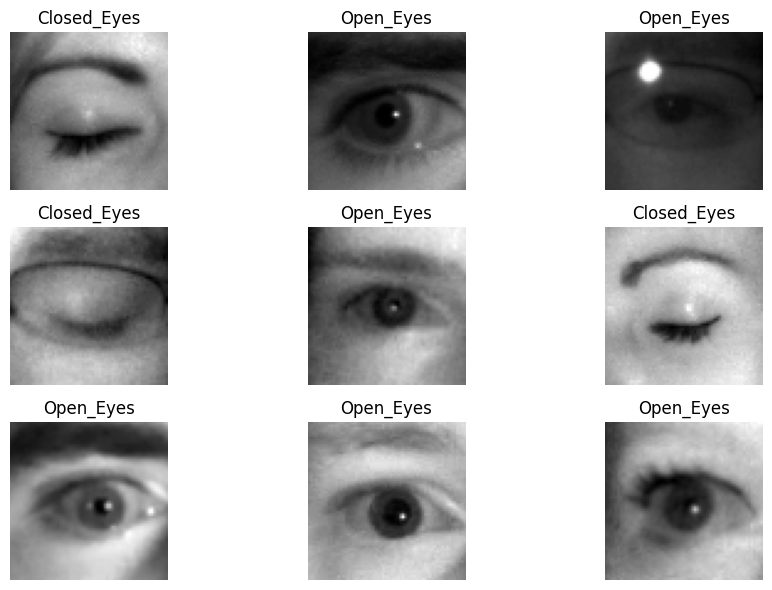

In [ ]:
plt.figure(figsize=(10, 6))

for images, labels in train_data.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title(class_names[int(labels[i])])
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model = models.Sequential([

    layers.Input(shape=(64, 64, 1)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 682,753 (2.60 MB)

 Trainable params: 682,753 (2.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 30s 284ms/step - accuracy: 0.8625 - loss: 0.2813 - val_accuracy: 0.9825 - val_loss: 0.0582
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 267ms/step - accuracy: 0.9803 - loss: 0.0621 - val_accuracy: 0.9762 - val_loss: 0.0758
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 25s 251ms/step - accuracy: 0.9887 - loss: 0.0347 - val_accuracy: 0.9900 - val_loss: 0.0427
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 248ms/step - accuracy: 0.9900 - loss: 0.0238 - val_accuracy: 0.9875 - val_loss: 0.0415
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 44s 277ms/step - accuracy: 0.9972 - loss: 0.0107 - val_accuracy: 0.9950 - val_loss: 0.0101
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 272ms/step - accuracy: 0.9975 - loss: 0.0080 - val_accuracy: 0.9987 - val_loss: 0.0061
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 328ms/step - accuracy: 0.9969 - loss: 0.0118 - val_accuracy: 0.9975 - val_loss: 0.0058
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 29s 293ms/step - accuracy: 0.9969 - loss: 0

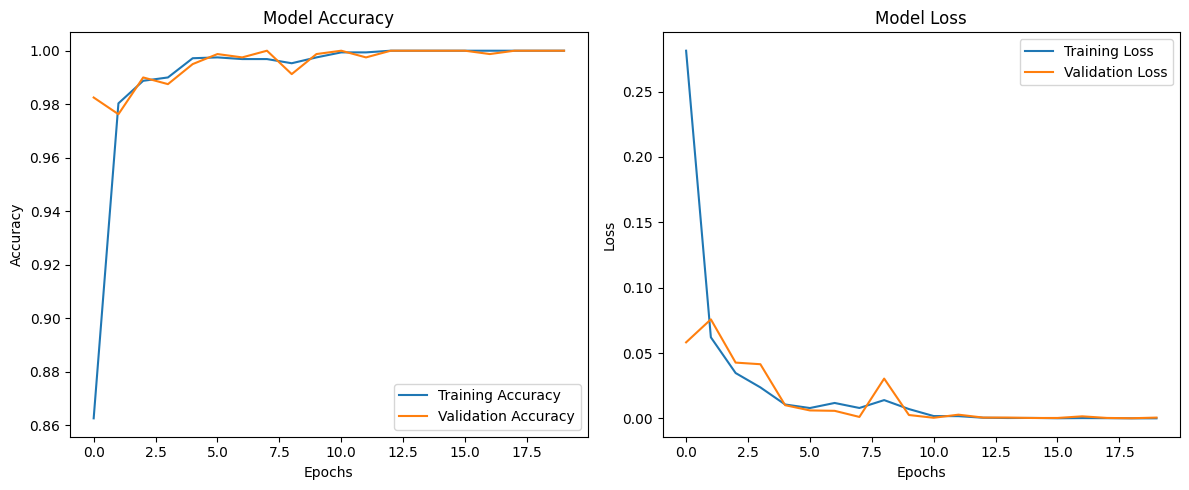

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 1.0000 - loss: 1.6276e-04
Validation Loss: 0.000162760479724966
Validation Accuracy: 100.0 %


In [ ]:
y_true = np.concatenate([
    labels.numpy() for images, labels in val_data
])

predictions = model.predict(val_data)

y_pred = (predictions.ravel() >= 0.5).astype(int)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 192ms/step
              precision    recall  f1-score   support

 Closed_Eyes       0.47      0.47      0.47       386
   Open_Eyes       0.50      0.50      0.50       414

    accuracy                           0.49       800
   macro avg       0.49      0.49      0.49       800
weighted avg       0.49      0.49      0.49       800

Confusion Matrix:
[[181 205]
 [205 209]]


In [ ]:
model.save("driver_drowsiness_model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!


In [ ]:
img_path = "test_eye.png"

img = image.load_img(
    img_path,
    target_size=(64, 64),
    color_mode="grayscale"
)

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)[0][0]

if prediction >= 0.5:
    print("Prediction: OPEN EYES")
else:
    print("Prediction: CLOSED EYES")

FileNotFoundError: [Errno 2] No such file or directory: 'test_eye.png'